# Week 6 — Predictive Analytics
### *What will happen?* Predict whether a review is a **high rating** (4+ stars)
**SENG 42293 Big Data Analytics · LO3**

Predictive analytics learns patterns from labelled history to predict an unknown. The craft is not the algorithm; it is **framing the problem, splitting the data honestly, choosing the right metric, and refusing to fool yourself**.

**In this notebook:** problem framing · baseline · train/validation/test discipline · logistic regression, random forest, gradient boosting · metrics (accuracy, precision, recall, F1, ROC-AUC) · thresholds and costs · overfitting · **data leakage** · regression · feature importance · the same model in **Spark MLlib**.

**Business question:** *Given what we know when a review is posted, can we flag likely high-rated reviews (e.g. to feature them on the hotel page)?*

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
ACC, ACCL, CH, GREY = "#8b7355", "#c4b5a0", "#2a2a2a", "#999999"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=[ACC, "#2a2a2a", ACCL, "#b5651d", "#6b8e8e", GREY]),
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
RES = {}                      # key numbers, reused in the slides and notes
def save(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", dpi=130); plt.show()

In [2]:
from sklearn.model_selection import train_test_split, cross_val_score, GroupKFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve, mean_squared_error)
from sklearn.inspection import permutation_importance

df = pd.read_csv("data/reviews_clean.csv", parse_dates=["review_date"]).dropna(subset=["rating"]).reset_index(drop=True)
df["high"] = (df.rating >= 4).astype(int)
df["has_votes"] = df.helpful_votes.notna().astype(int); df["helpful_votes"] = df.helpful_votes.fillna(0)
df["month_num"] = df.review_date.dt.month
print(df.shape, "| share high:", round(df.high.mean(), 3))

(15183, 22) | share high: 0.459


## 1. Frame the problem
* **Target:** `high` = rating >= 4 (binary classification).
* **Features known at prediction time:** hotel stars, city, review length, helpful votes, number of tags, month. (We deliberately leave the review *text* out for now: section 5 adds it and shows why a suspiciously good result must be questioned.)
* **Not allowed:** anything computed from the rating itself (that is *leakage*, section 7).

In [3]:
df["tags_n"] = df.tags.fillna("").apply(lambda t: 0 if t == "" else len(t.split("|")))
num = ["stars", "n_words", "helpful_votes", "has_votes", "tags_n", "month_num"]; cat = ["city"]
X, y = df[num + cat], df["high"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, random_state=42, stratify=y)
print(f"train {len(Xtr):,}  test {len(Xte):,}  | high rate train {ytr.mean():.3f} test {yte.mean():.3f}")

train 11,387  test 3,796  | high rate train 0.459 test 0.459


**Rule 1: the test set is touched once, at the very end.** Use cross-validation on the training set to compare models.

## 2. Baseline first
A model is only useful if it beats something simple. The *majority-class* baseline predicts 'high' always (or never).

In [4]:
base_acc = max(ytr.mean(), 1 - ytr.mean())
base_auc = 0.5
print(f"majority-class accuracy: {base_acc:.3f}  (AUC of a coin flip = 0.5)")
RES["base_acc"] = round(base_acc, 3)

majority-class accuracy: 0.541  (AUC of a coin flip = 0.5)


## 3. Three models, compared with cross-validation

In [5]:
pre = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
models = {
  "Logistic regression": Pipeline([("pre", pre), ("m", LogisticRegression(max_iter=1000))]),
  "Random forest":       Pipeline([("pre", pre), ("m", RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=0))]),
  "Gradient boosting":   Pipeline([("pre", pre), ("m", HistGradientBoostingClassifier(random_state=0))]),
}
cv = StratifiedKFold(5, shuffle=True, random_state=0)
rows = []
for name, m in models.items():
    s = cross_val_score(m, Xtr, ytr, cv=cv, scoring="roc_auc")
    rows.append((name, s.mean(), s.std())); print(f"{name:22s} CV AUC = {s.mean():.3f} +/- {s.std():.3f}")
cvdf = pd.DataFrame(rows, columns=["model", "auc", "sd"])

Logistic regression    CV AUC = 0.592 +/- 0.005


Random forest          CV AUC = 0.686 +/- 0.009


Gradient boosting      CV AUC = 0.698 +/- 0.013


Cross-validation gives a mean **and a spread**. If two models differ by less than the spread, you cannot claim one is better. Here the tree models beat logistic regression by a wide margin: the relationship between some features and the outcome is **non-linear** (section 9 shows which). We carry the best model, gradient boosting, forward.

## 4. Final evaluation on the held-out test set

,test
accuracy,0.643
precision,0.577
recall,0.830
f1,0.681
auc,0.685


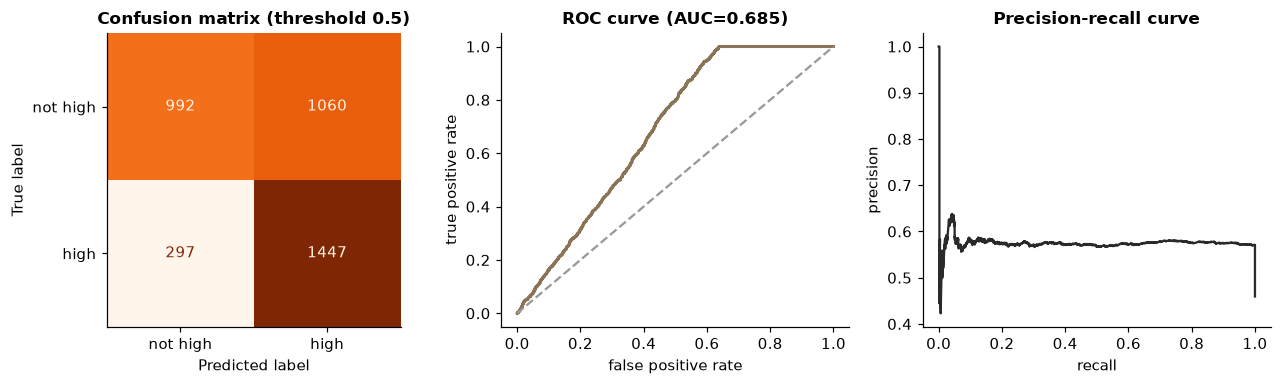

In [6]:
lr_auc = roc_auc_score(yte, models["Logistic regression"].fit(Xtr, ytr).predict_proba(Xte)[:, 1])       # kept for the Spark comparison
best = models["Gradient boosting"].fit(Xtr, ytr)          # best model by cross-validation
p = best.predict_proba(Xte)[:, 1]; pred = (p >= .5).astype(int)
met = dict(accuracy=accuracy_score(yte, pred), precision=precision_score(yte, pred), recall=recall_score(yte, pred), f1=f1_score(yte, pred), auc=roc_auc_score(yte, p))
display(pd.Series(met).round(3).to_frame("test"))
RES["gb_test"] = {k: round(float(v), 3) for k, v in met.items()}
RES["cv"] = {r[0]: round(float(r[1]), 3) for r in rows}
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=["not high", "high"]).plot(ax=ax[0], cmap="Oranges", colorbar=False); ax[0].set_title("Confusion matrix (threshold 0.5)")
fpr, tpr, _ = roc_curve(yte, p); ax[1].plot(fpr, tpr, color=ACC, lw=2); ax[1].plot([0, 1], [0, 1], ls="--", color=GREY); ax[1].set_title(f"ROC curve (AUC={met['auc']:.3f})"); ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate")
pr, rc, th = precision_recall_curve(yte, p); ax[2].plot(rc, pr, color=CH); ax[2].set_title("Precision-recall curve"); ax[2].set_xlabel("recall"); ax[2].set_ylabel("precision")
save("w06_evaluation")

| Metric | Question it answers |
|---|---|
| Accuracy | share of all predictions that are right (misleading if classes are unbalanced) |
| Precision | of reviews we *flag* as high, how many really are? |
| Recall | of all truly high reviews, how many did we *find*? |
| F1 | harmonic mean of precision and recall |
| ROC-AUC | probability a random high review scores above a random not-high one |

## 4b. Adding the text signal: when a result is too good to be true
The lexicon sentiment of the review text is available the moment a review is posted, so it is a legitimate feature. Let us add it.

In [7]:
num_t = num + ["sentiment"]
pre_t = ColumnTransformer([("num", StandardScaler(), num_t), ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
Xt = df[num_t + cat]; a, b, c, d = train_test_split(Xt, y, test_size=.25, random_state=42, stratify=y)
m_t = Pipeline([("pre", pre_t), ("m", LogisticRegression(max_iter=1000))]).fit(a, c)
auc_text = roc_auc_score(d, m_t.predict_proba(b)[:, 1])
print(f"logistic regression: metadata only AUC = {lr_auc:.3f} | + text sentiment AUC = {auc_text:.3f}")
RES["auc_meta"], RES["auc_text"] = round(float(lr_auc), 3), round(float(auc_text), 3)

logistic regression: metadata only AUC = 0.588 | + text sentiment AUC = 0.999


**AUC jumps to nearly 1.0.** On real reviews, text sentiment is strongly predictive but never *this* clean. Here the synthetic review text was generated *from* the rating, so the lexicon almost reads the answer off. This is an example of **target leakage by construction**: a good habit is to ask, *why is this so good?* before celebrating.

## 5. The threshold is a business decision
The default 0.5 is arbitrary. If featuring a poor review is costly, raise the threshold; if missing good ones is costly, lower it.

,threshold,precision,recall,f1,share_flagged
0,0.3,0.571,0.999,0.727,0.805
1,0.4,0.572,0.971,0.720,0.780
2,0.5,0.577,0.830,0.681,0.660
3,0.6,0.572,0.320,0.410,0.257
4,0.7,0.580,0.027,0.052,0.021
5,0.8,1.000,0.002,0.005,0.001


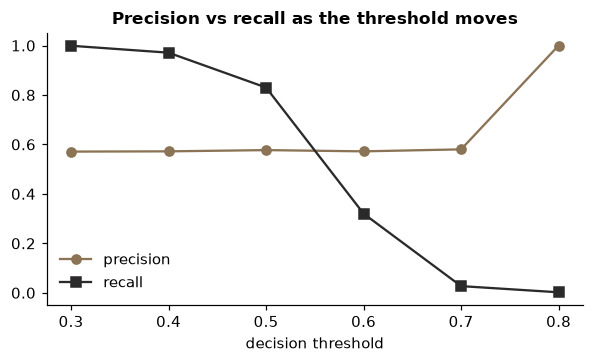

In [8]:
rows = []
for t in [.3, .4, .5, .6, .7, .8]:
    pr_ = (p >= t).astype(int); rows.append((t, precision_score(yte, pr_), recall_score(yte, pr_), f1_score(yte, pr_), pr_.mean()))
thr = pd.DataFrame(rows, columns=["threshold", "precision", "recall", "f1", "share_flagged"]).round(3); display(thr)
RES["thr_table"] = thr.to_dict("records")
fig, ax = plt.subplots(figsize=(5.5, 3.4)); ax.plot(thr.threshold, thr.precision, "o-", color=ACC, label="precision"); ax.plot(thr.threshold, thr.recall, "s-", color=CH, label="recall")
ax.set_xlabel("decision threshold"); ax.set_title("Precision vs recall as the threshold moves"); ax.legend(frameon=False); save("w06_threshold")

## 6. Overfitting: the gap between training and test
A flexible model can memorise the training data. Watch the **train vs validation gap** as complexity grows.

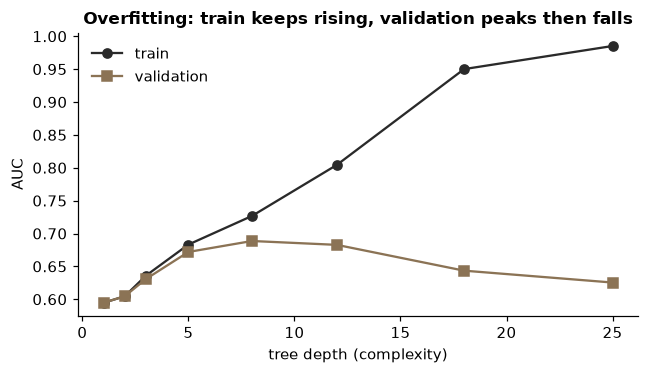

best depth: 8 | train AUC at depth 25: 0.985 | validation: 0.625


In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import validation_curve
Xtr_t = pre.fit_transform(Xtr); depths = [1, 2, 3, 5, 8, 12, 18, 25]
tr, va = validation_curve(DecisionTreeClassifier(random_state=0), Xtr_t, ytr, param_name="max_depth", param_range=depths, cv=5, scoring="roc_auc")
fig, ax = plt.subplots(figsize=(6, 3.5)); ax.plot(depths, tr.mean(1), "o-", color=CH, label="train"); ax.plot(depths, va.mean(1), "s-", color=ACC, label="validation")
ax.set_xlabel("tree depth (complexity)"); ax.set_ylabel("AUC"); ax.set_title("Overfitting: train keeps rising, validation peaks then falls"); ax.legend(frameon=False); save("w06_overfit")
bd = depths[int(va.mean(1).argmax())]; print("best depth:", bd, "| train AUC at depth 25:", round(tr.mean(1)[-1], 3), "| validation:", round(va.mean(1)[-1], 3))
RES["overfit"] = {"best_depth": bd, "train_auc_deep": round(float(tr.mean(1)[-1]), 3), "val_auc_deep": round(float(va.mean(1)[-1]), 3)}

## 7. Data leakage: the silent killer
**Leakage** is when information that would *not be available at prediction time* sneaks into training. Results look wonderful and collapse in production.

Two examples on our data:
1. **Target-derived feature:** the hotel's *mean rating computed over all its reviews, including the one we predict*.
2. **Group leakage:** the same hotel appears in train and test, so the model can recognise the hotel instead of learning general patterns.

In [10]:
leak = df.copy()
leak["hotel_mean_all"] = leak.groupby("hotel_id").rating.transform("mean")          # includes the row's own rating!
# honest version: leave-one-out (exclude the row itself)
g = leak.groupby("hotel_id").rating; s, n = g.transform("sum"), g.transform("count")
leak["hotel_mean_loo"] = (s - leak.rating) / (n - 1)
def auc_with(extra, split="random"):
    cols = num + extra; Xl = leak[cols + cat]; pre_ = ColumnTransformer([("num", StandardScaler(), cols), ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    m = Pipeline([("pre", pre_), ("m", LogisticRegression(max_iter=1000))])
    if split == "random": a, b, c, d = train_test_split(Xl, leak.high, test_size=.25, random_state=42, stratify=leak.high)
    else:
        tr_idx, te_idx = next(GroupKFold(4).split(Xl, leak.high, groups=leak.hotel_id)); a, b, c, d = Xl.iloc[tr_idx], Xl.iloc[te_idx], leak.high.iloc[tr_idx], leak.high.iloc[te_idx]
    return roc_auc_score(d, m.fit(a, c).predict_proba(b)[:, 1])
res = {"no hotel feature": auc_with([]), "hotel mean incl. own row (LEAK)": auc_with(["hotel_mean_all"]), "hotel mean leave-one-out (honest)": auc_with(["hotel_mean_loo"])}
for k, v in res.items(): print(f"{k:38s} test AUC = {v:.4f}")
RES["leak"] = {k: round(float(v), 4) for k, v in res.items()}

no hotel feature                       test AUC = 0.5876
hotel mean incl. own row (LEAK)        test AUC = 0.6835
hotel mean leave-one-out (honest)      test AUC = 0.6624


random split AUC = 0.6624 | hotels held out AUC = 0.6460


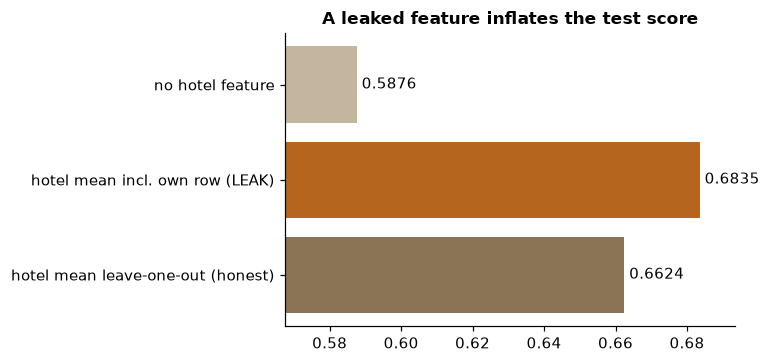

In [11]:
# Group leakage: random split vs hold out WHOLE hotels, using the (honest) hotel-mean feature
g_rand = auc_with(["hotel_mean_loo"], "random"); g_group = auc_with(["hotel_mean_loo"], "group")
print(f"random split AUC = {g_rand:.4f} | hotels held out AUC = {g_group:.4f}")
RES["group_split"] = {"random": round(float(g_rand), 4), "grouped": round(float(g_group), 4)}
fig, ax = plt.subplots(figsize=(7, 3.4)); names = list(res.keys()); vals = list(res.values())
ax.barh(names, vals, color=[ACCL, "#b5651d", ACC]); ax.set_xlim(min(vals) - .02, max(vals) + .01); ax.set_title("A leaked feature inflates the test score"); ax.invert_yaxis()
for i, v in enumerate(vals): ax.text(v, i, f" {v:.4f}", va="center")
save("w06_leakage")

**Rule 2: if a result looks too good, suspect leakage.** Ask of every feature: *would I know this value at the moment I make the prediction?*  For time-ordered data, split by **time**, not at random.

## 8. Regression: predict the rating itself
When the target is a number, the error metric is RMSE (same units as the target). The baseline predicts the training mean.

baseline RMSE (predict the mean) = 0.986 | gradient boosting RMSE = 0.875 | improvement = 11.3%


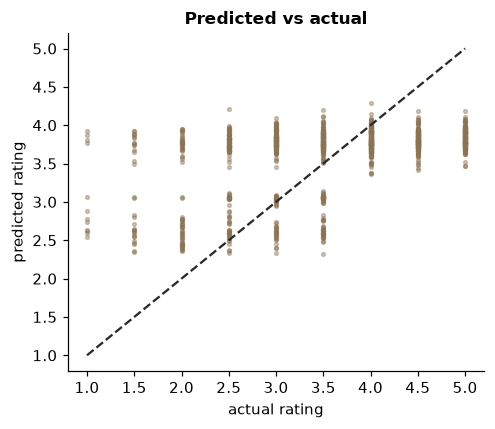

In [12]:
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(df[num + cat], df.rating, test_size=.25, random_state=42)
base_rmse = np.sqrt(mean_squared_error(yr_te, np.full(len(yr_te), yr_tr.mean())))
reg = Pipeline([("pre", pre), ("m", HistGradientBoostingRegressor(random_state=0))]).fit(Xr_tr, yr_tr)
rmse = np.sqrt(mean_squared_error(yr_te, reg.predict(Xr_te)))
print(f"baseline RMSE (predict the mean) = {base_rmse:.3f} | gradient boosting RMSE = {rmse:.3f} | improvement = {(1 - rmse / base_rmse):.1%}")
RES["reg"] = {"base_rmse": round(float(base_rmse), 3), "gbm_rmse": round(float(rmse), 3)}
fig, ax = plt.subplots(figsize=(4.6, 4)); idx = np.random.default_rng(0).choice(len(yr_te), 1200, replace=False)
ax.scatter(yr_te.iloc[idx], reg.predict(Xr_te.iloc[idx]), s=6, alpha=.4, color=ACC); ax.plot([1, 5], [1, 5], ls="--", color=CH)
ax.set_xlabel("actual rating"); ax.set_ylabel("predicted rating"); ax.set_title("Predicted vs actual"); save("w06_regression")

## 9. What drives the predictions? (permutation importance)
Shuffle one feature at a time on the test set; the drop in AUC shows how much the model relied on it.

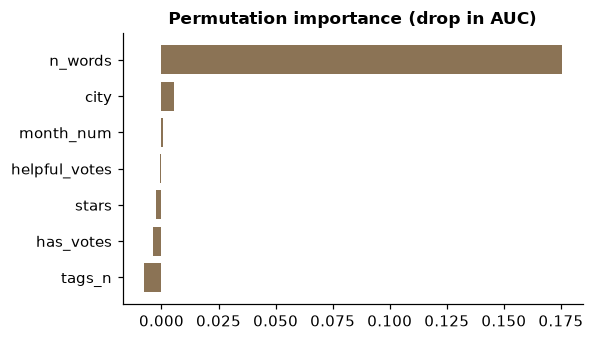

tags_n          -0.0078
has_votes       -0.0037
stars           -0.0026
helpful_votes   -0.0008
month_num        0.0007
city             0.0057
n_words          0.1753


In [13]:
gb = models["Gradient boosting"].fit(Xtr, ytr)  # metadata-only features
pi = permutation_importance(gb, Xte, yte, scoring="roc_auc", n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values()
fig, ax = plt.subplots(figsize=(5.5, 3.2)); ax.barh(imp.index, imp.values, color=ACC); ax.set_title("Permutation importance (drop in AUC)"); save("w06_importance")
RES["top_feature"] = imp.index[-1]; print(imp.round(4).to_string())

## 10. The same idea in Spark MLlib (scales to a cluster)
Same problem, expressed as a Spark `Pipeline`. The model is fit in parallel on partitions of the data.

In [14]:
import sys; os.environ["PYSPARK_PYTHON"] = sys.executable
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline as SPipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder as SOHE, VectorAssembler, StandardScaler as SScaler
from pyspark.ml.classification import LogisticRegression as SLR
from pyspark.ml.evaluation import BinaryClassificationEvaluator
spark = SparkSession.builder.master("local[*]").config("spark.ui.enabled", "false").getOrCreate(); spark.sparkContext.setLogLevel("ERROR")
sdf = (spark.read.csv("data/reviews_clean.csv", header=True, inferSchema=True).filter(F.col("rating").isNotNull())
       .withColumn("label", (F.col("rating") >= 4).cast("double")).withColumn("helpful_votes", F.coalesce("helpful_votes", F.lit(0)))
       .withColumn("month_num", F.month("review_date")))
train, test = sdf.randomSplit([.75, .25], seed=42)
stages = [StringIndexer(inputCol="city", outputCol="city_ix"), SOHE(inputCols=["city_ix"], outputCols=["city_oh"]),
          VectorAssembler(inputCols=["city_oh", "stars", "n_words", "helpful_votes", "month_num"], outputCol="raw"),
          SScaler(inputCol="raw", outputCol="features"), SLR(featuresCol="features", labelCol="label", maxIter=50)]
model = SPipeline(stages=stages).fit(train)
auc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC").evaluate(model.transform(test))
print(f"Spark MLlib logistic regression AUC = {auc:.4f}   (scikit-learn: {lr_auc:.4f})")
RES["spark_auc"] = round(float(auc), 4); spark.stop()

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=44265 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=44265 -Dhttp.nonProxyHosts=localhost|127.0.0.1

26/10/13 08:39:28 WARN Utils: Your hostname, vm resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/10/13 08:39:29 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/13 08:39:29 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark MLlib logistic regression AUC = 0.5847   (scikit-learn: 0.5876)


**Rule of thumb:** prototype with scikit-learn on a sample; move to Spark MLlib when the data no longer fits in one machine's memory. Expect similar accuracy and a different API.

## 11. Exercises
1. Use `sentiment` as the *only* feature. What AUC do you get, and what does that say about how the data was generated?
2. Pick a threshold that guarantees at least 90% precision. What recall do you get?
3. Split **by time** (train on the earliest 75% of dates, test on the latest 25%). Is the AUC different from the random split?
4. In section 7, which is more damaging in production: the leaked feature or the group split? Explain in two sentences.
5. Plot mean rating against `n_words`. Why do tree models exploit it while logistic regression cannot?
6. The data is synthetic and sentiment is generated from the rating. Which results here would you *not* expect to reproduce on real reviews?

In [15]:
json.dump(RES, open("results/w06.json", "w"), indent=1); print(json.dumps(RES, indent=1)[:1800])

{
 "base_acc": 0.541,
 "gb_test": {
  "accuracy": 0.643,
  "precision": 0.577,
  "recall": 0.83,
  "f1": 0.681,
  "auc": 0.685
 },
 "cv": {
  "Logistic regression": 0.592,
  "Random forest": 0.686,
  "Gradient boosting": 0.698
 },
 "auc_meta": 0.588,
 "auc_text": 0.999,
 "thr_table": [
  {
   "threshold": 0.3,
   "precision": 0.571,
   "recall": 0.999,
   "f1": 0.727,
   "share_flagged": 0.805
  },
  {
   "threshold": 0.4,
   "precision": 0.572,
   "recall": 0.971,
   "f1": 0.72,
   "share_flagged": 0.78
  },
  {
   "threshold": 0.5,
   "precision": 0.577,
   "recall": 0.83,
   "f1": 0.681,
   "share_flagged": 0.66
  },
  {
   "threshold": 0.6,
   "precision": 0.572,
   "recall": 0.32,
   "f1": 0.41,
   "share_flagged": 0.257
  },
  {
   "threshold": 0.7,
   "precision": 0.58,
   "recall": 0.027,
   "f1": 0.052,
   "share_flagged": 0.021
  },
  {
   "threshold": 0.8,
   "precision": 1.0,
   "recall": 0.002,
   "f1": 0.005,
   "share_flagged": 0.001
  }
 ],
 "overfit": {
  "best_depth":